In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("weatherAUS.csv")
df=df.drop_duplicates()

In [4]:
null_percentage = df.isnull().mean() * 100
print(null_percentage)

Date              0.000000
Location          0.000000
MinTemp           1.020899
MaxTemp           0.866905
Rainfall          2.241853
Evaporation      43.166506
Sunshine         48.009762
WindGustDir       7.098859
WindGustSpeed     7.055548
WindDir9am        7.263853
WindDir3pm        2.906641
WindSpeed9am      1.214767
WindSpeed3pm      2.105046
Humidity9am       1.824557
Humidity3pm       3.098446
Pressure9am      10.356799
Pressure3pm      10.331363
Cloud9am         38.421559
Cloud3pm         40.807095
Temp9am           1.214767
Temp3pm           2.481094
RainToday         2.241853
RainTomorrow      2.245978
dtype: float64


In [5]:
#.index returns the index (column names) of the Series where the condition is True
columns_to_drop = null_percentage[null_percentage > 30].index
df.drop(columns=columns_to_drop ,axis=1, inplace=True)
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 19 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   WindGustDir    135134 non-null  object 
 6   WindGustSpeed  135197 non-null  float64
 7   WindDir9am     134894 non-null  object 
 8   WindDir3pm     141232 non-null  object 
 9   WindSpeed9am   143693 non-null  float64
 10  WindSpeed3pm   142398 non-null  float64
 11  Humidity9am    142806 non-null  float64
 12  Humidity3pm    140953 non-null  float64
 13  Pressure9am    130395 non-null  float64
 14  Pressure3pm    130432 non-null  float64
 15  Temp9am        143693 non-null  float64
 16  Temp3pm        141851 non-null  float64
 17  RainToday      142199 non-nul

In [6]:
df['MinTemp']=df['MinTemp'].fillna(df['MinTemp'].median())
df['MaxTemp']=df['MaxTemp'].fillna(df['MaxTemp'].median())
df['Rainfall']=df['Rainfall'].fillna(df['Rainfall'].median())
df['WindGustSpeed']=df['WindGustSpeed'].fillna(df['WindGustSpeed'].median())
df['WindSpeed9am']=df['WindSpeed9am'].fillna(df['WindSpeed9am'].median())
df['WindSpeed3pm']=df['WindSpeed3pm'].fillna(df['WindSpeed3pm'].median())
df['Humidity9am']=df['Humidity9am'].fillna(df['Humidity9am'].median())
df['Humidity3pm']=df['Humidity3pm'].fillna(df['Humidity3pm'].median())
df['Pressure9am']=df['Pressure9am'].fillna(df['Pressure9am'].median())
df['Pressure3pm']=df['Pressure3pm'].fillna(df['Pressure3pm'].median())
df['Temp9am']=df['Temp9am'].fillna(df['Temp9am'].median())
df['Temp3pm']=df['Temp3pm'].fillna(df['Temp3pm'].median())
#to check if there are any null values left in the dataset for numerical data
print(df.isnull().sum())

Date                 0
Location             0
MinTemp              0
MaxTemp              0
Rainfall             0
WindGustDir      10326
WindGustSpeed        0
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am         0
WindSpeed3pm         0
Humidity9am          0
Humidity3pm          0
Pressure9am          0
Pressure3pm          0
Temp9am              0
Temp3pm              0
RainToday         3261
RainTomorrow      3267
dtype: int64


In [7]:
#treating categorical data
df['RainToday']=df['RainToday'].fillna(df['RainToday'].mode()[0])
df['RainTomorrow']=df['RainTomorrow'].fillna(df['RainTomorrow'].mode()[0])
df['WindGustDir']=df['WindGustDir'].fillna(df['WindGustDir'].mode()[0])
df['WindDir9am']=df['WindDir9am'].fillna(df['WindDir9am'].mode()[0])
df['WindDir3pm']=df['WindDir3pm'].fillna(df['WindDir3pm'].mode()[0])
#to check if there are any null values left in the dataset for categorical data
#what is the use of [0]?
# The [0] is used to extract the first value from the mode() result, which is a pandas Series
#elaborate on the use of [0] in the context of mode() function in pandas
# The mode() function returns a pandas Series containing the most frequently occurring value(s). By using [0], we select the first value from this series.
print(df.isnull().sum())

Date             0
Location         0
MinTemp          0
MaxTemp          0
Rainfall         0
WindGustDir      0
WindGustSpeed    0
WindDir9am       0
WindDir3pm       0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Temp9am          0
Temp3pm          0
RainToday        0
RainTomorrow     0
dtype: int64


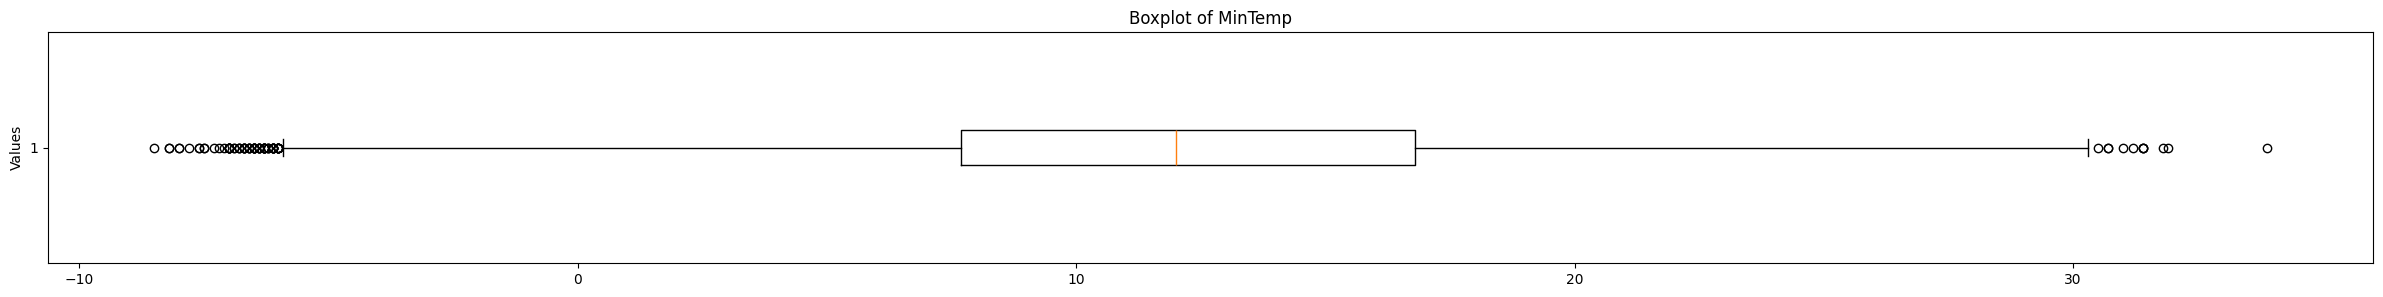

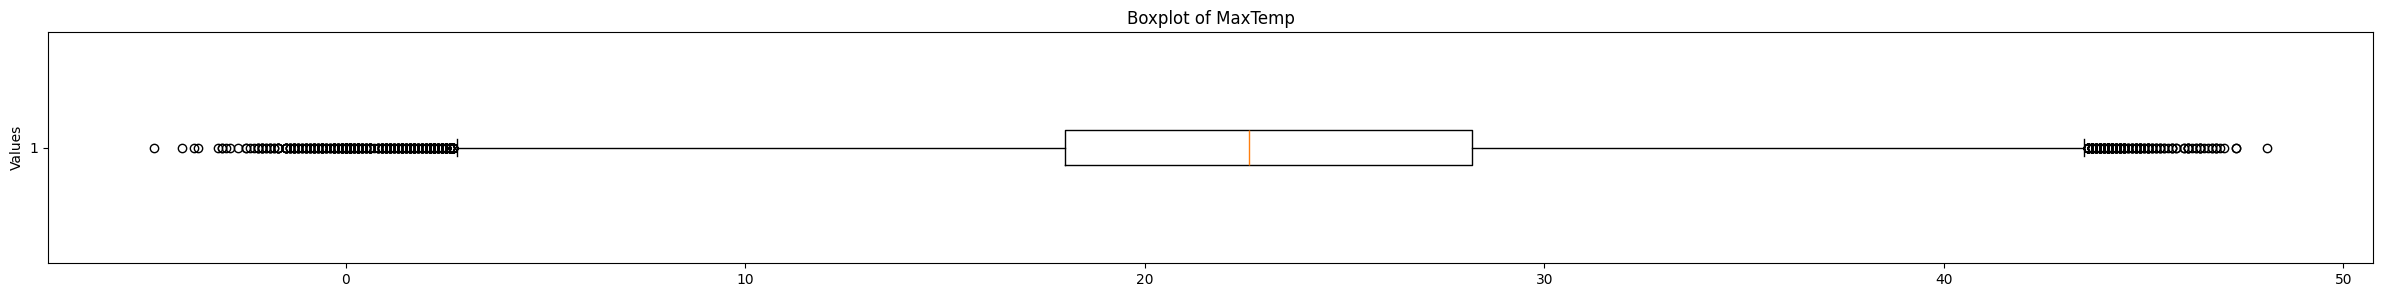

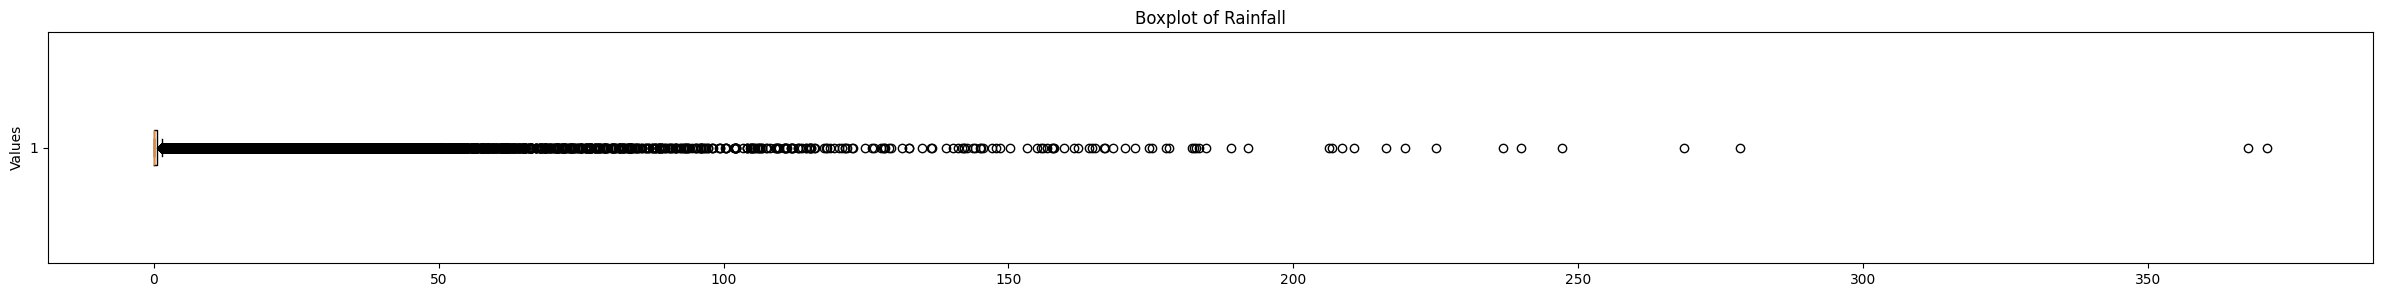

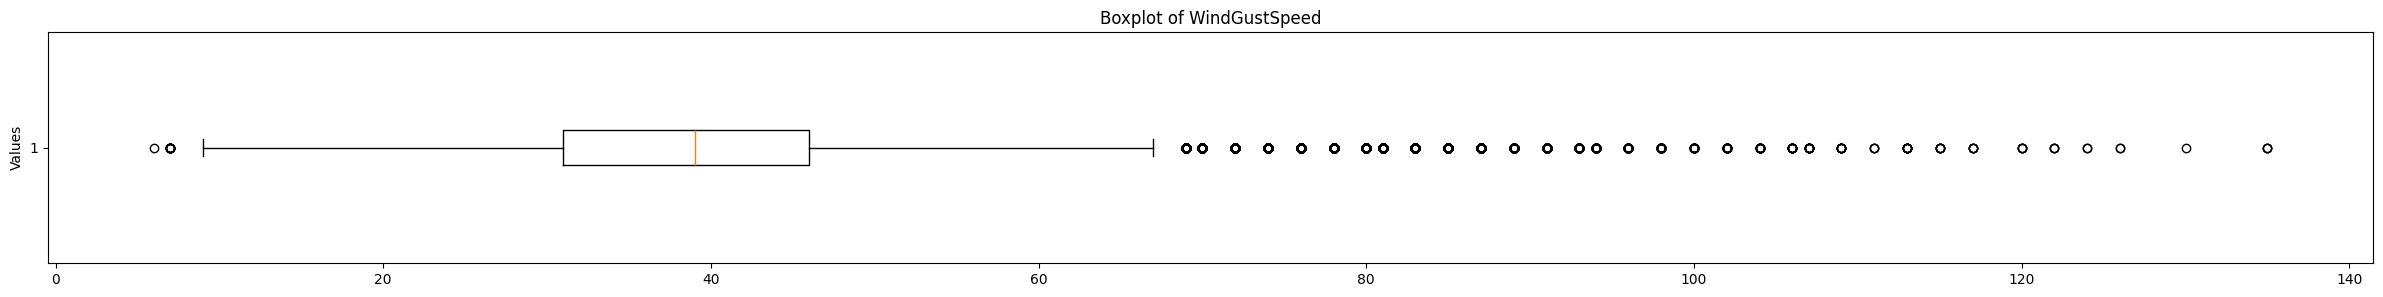

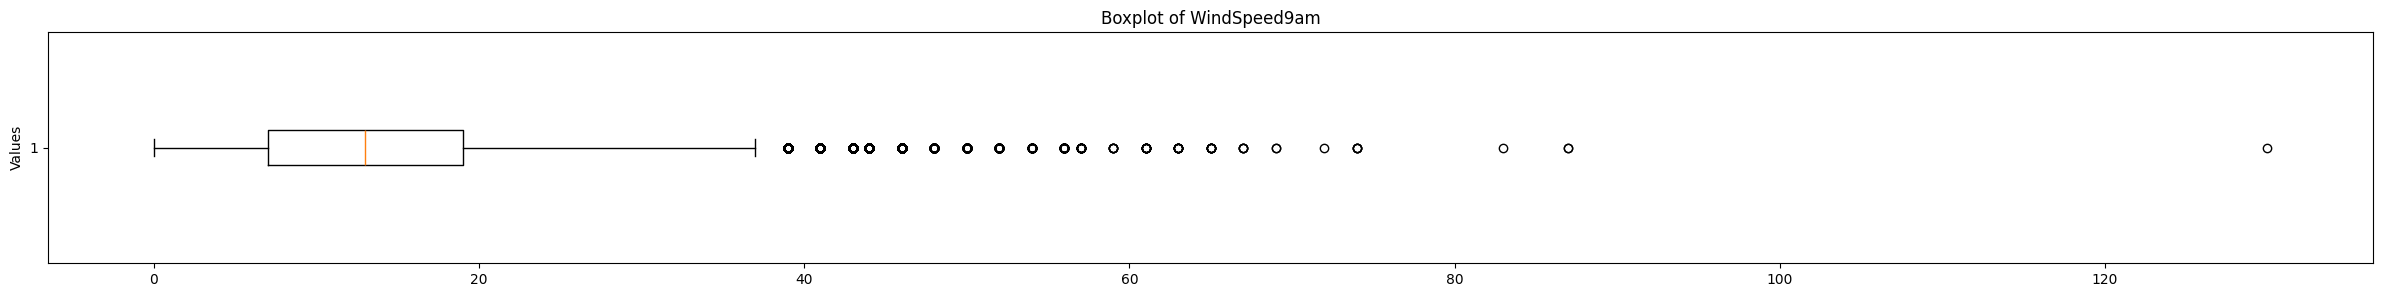

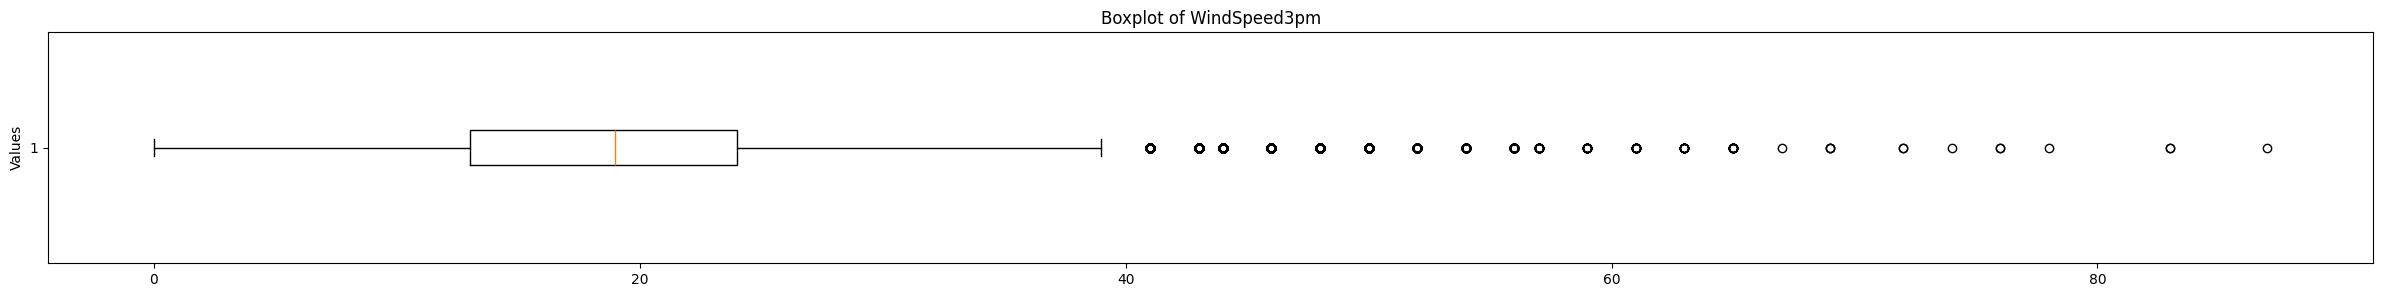

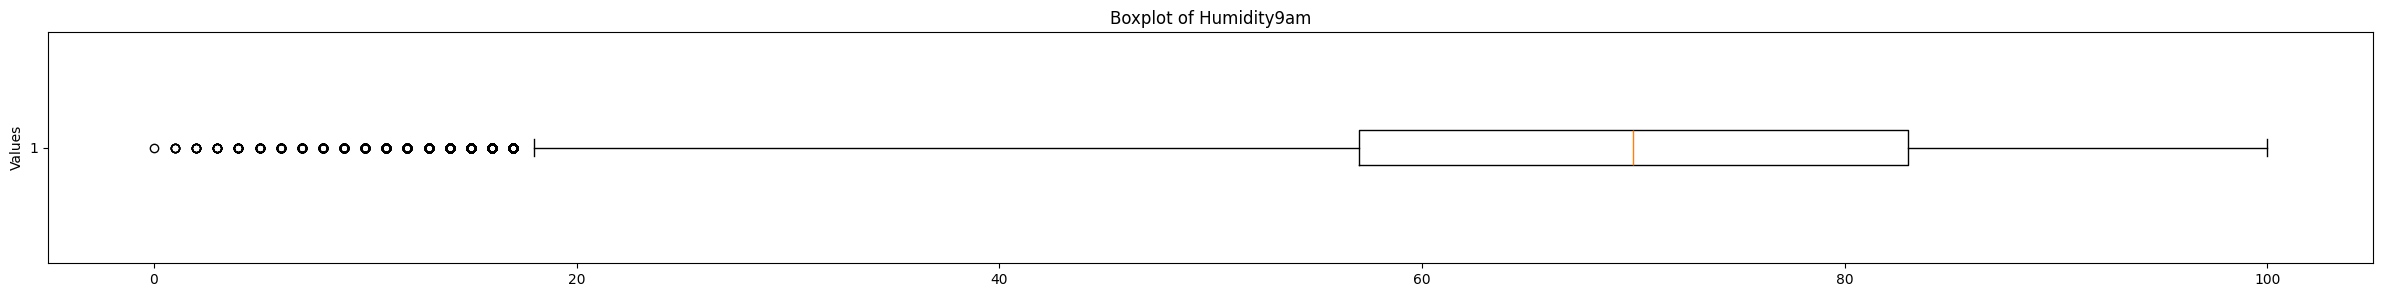

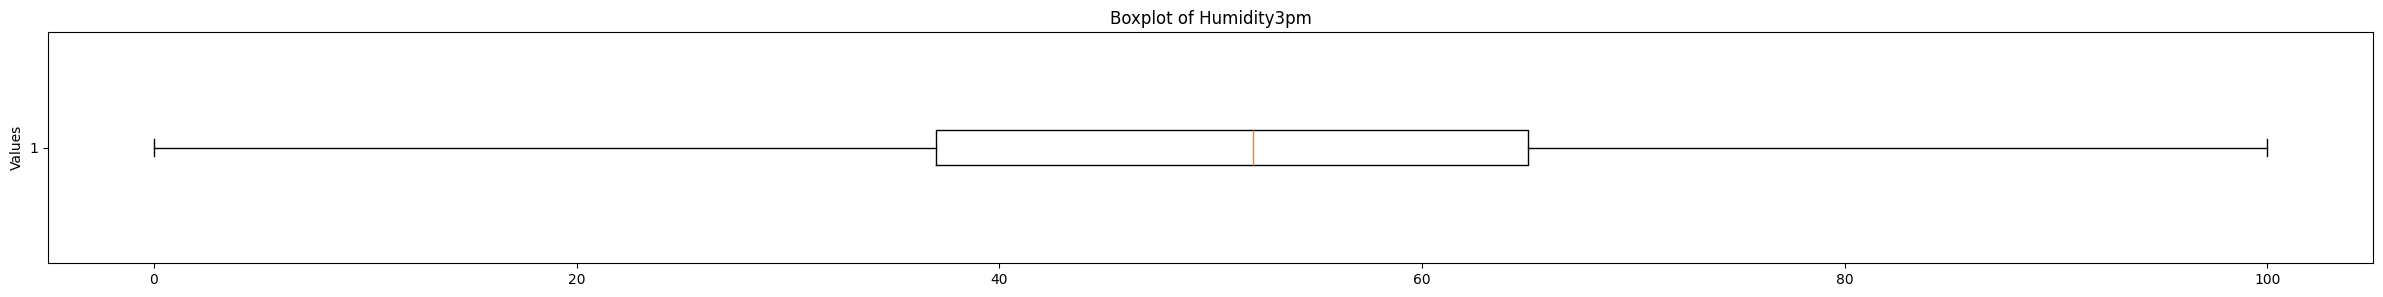

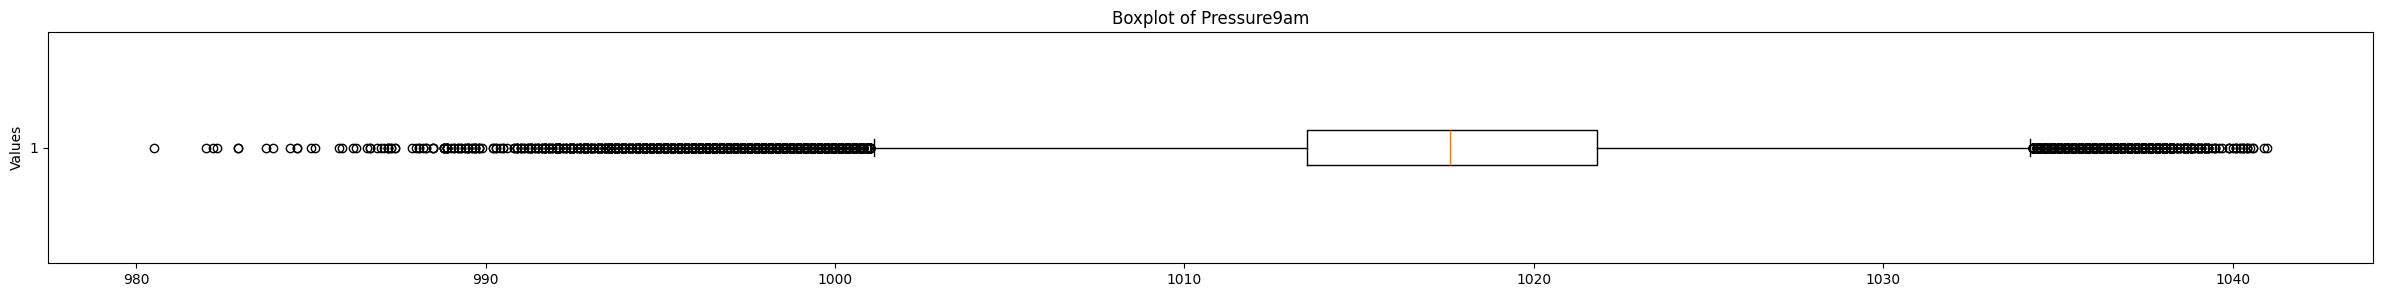

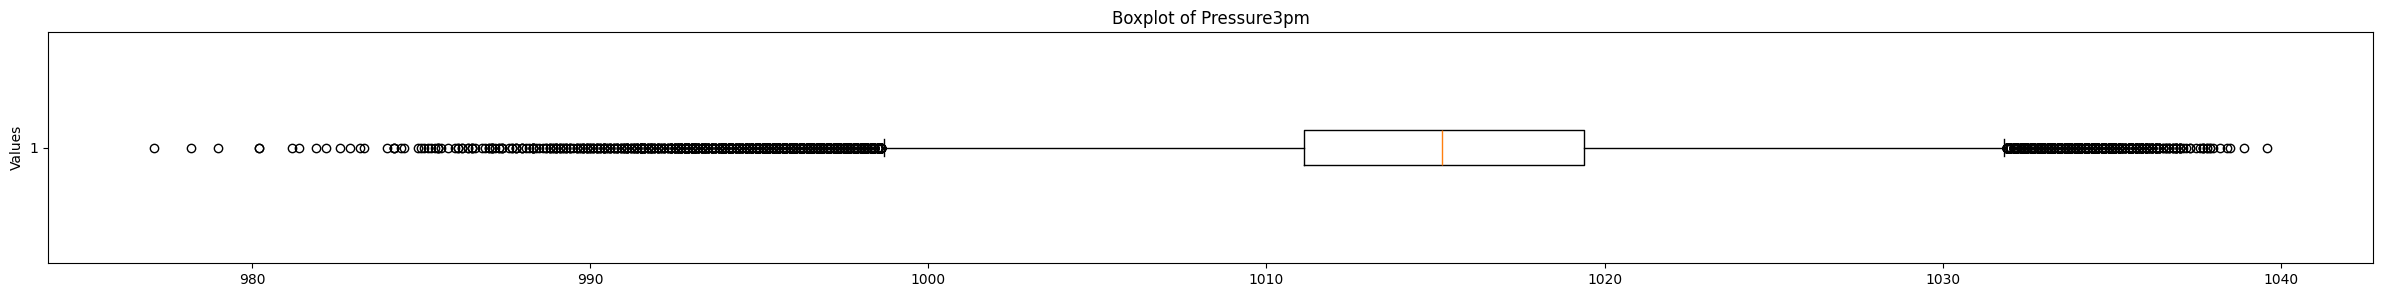

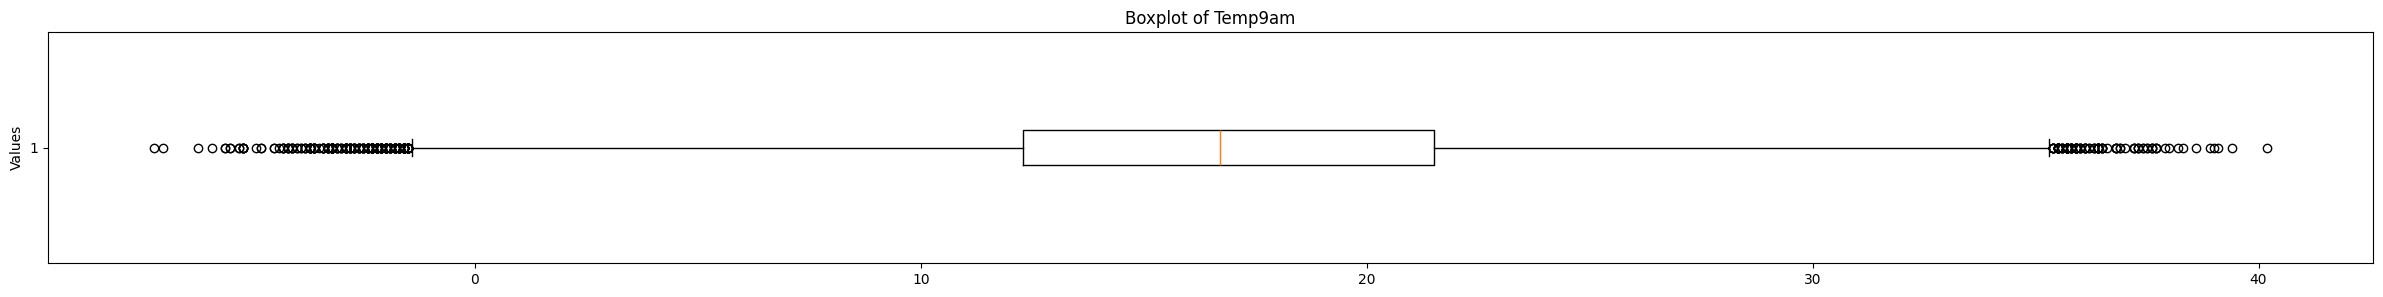

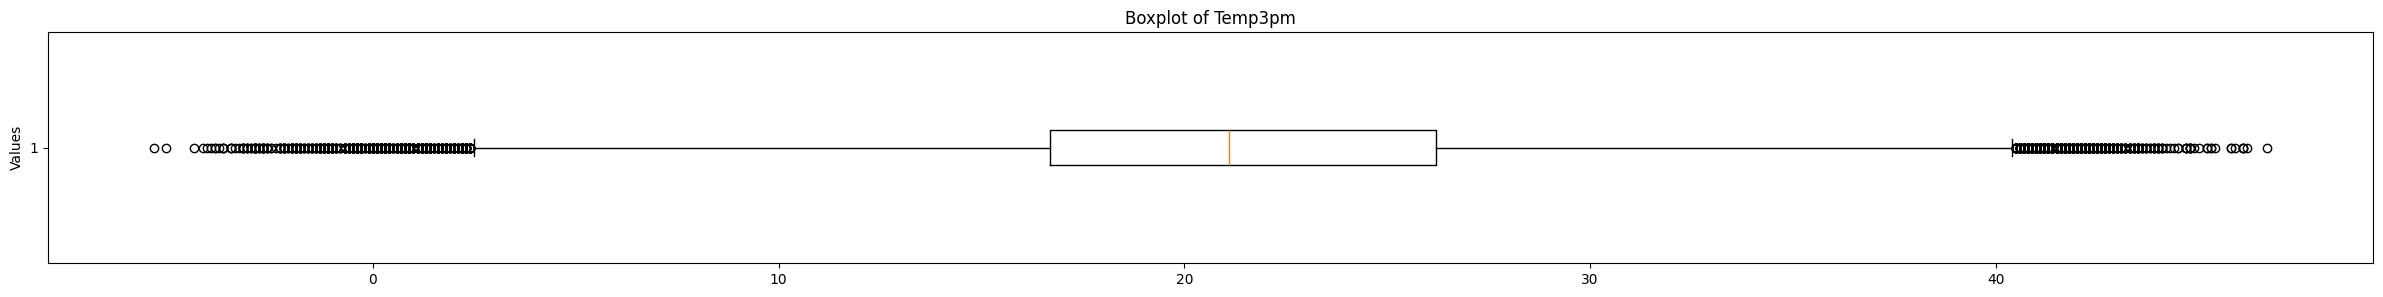

In [8]:


numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    plt.figure(figsize=(30, 3))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.ylabel("Values")
    plt.show()

In [9]:
df_clean = df.copy()
clean_numeric_cols = df_clean.select_dtypes(include="number").columns
for col in clean_numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]
    # plt.figure(figsize=(30, 3))
    # plt.boxplot(df_clean[col].dropna(), vert=False)
    # plt.title(f"Boxplot of {col}")
    # plt.ylabel("Values")
    # plt.show()    

In [10]:
#binary mapping
df_clean["RainToday"] = df_clean["RainToday"].map({"No": 0, "Yes": 1})
df_clean["RainTomorrow"] = df_clean["RainTomorrow"].map({"No": 0, "Yes": 1})
#data normalization
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_clean[df_clean.select_dtypes(include="number").columns] = scaler.fit_transform(
    df_clean.select_dtypes(include="number")
)
print(df_clean)

              Date Location   MinTemp   MaxTemp  Rainfall WindGustDir  \
0       01-12-2008   Albury  0.534626  0.492611  0.400000           W   
1       02-12-2008   Albury  0.368421  0.546798  0.000000         WNW   
2       03-12-2008   Albury  0.520776  0.561576  0.000000         WSW   
3       04-12-2008   Albury  0.418283  0.618227  0.000000          NE   
4       05-12-2008   Albury  0.648199  0.724138  0.666667           W   
...            ...      ...       ...       ...       ...         ...   
145455  21-06-2017    Uluru  0.240997  0.504926  0.000000           E   
145456  22-06-2017    Uluru  0.263158  0.551724  0.000000         NNW   
145457  23-06-2017    Uluru  0.313019  0.591133  0.000000           N   
145458  24-06-2017    Uluru  0.379501  0.593596  0.000000          SE   
145459  25-06-2017    Uluru  0.576177  0.485222  0.000000           W   

        WindGustSpeed WindDir9am WindDir3pm  WindSpeed9am  WindSpeed3pm  \
0                0.62          W        WNW     

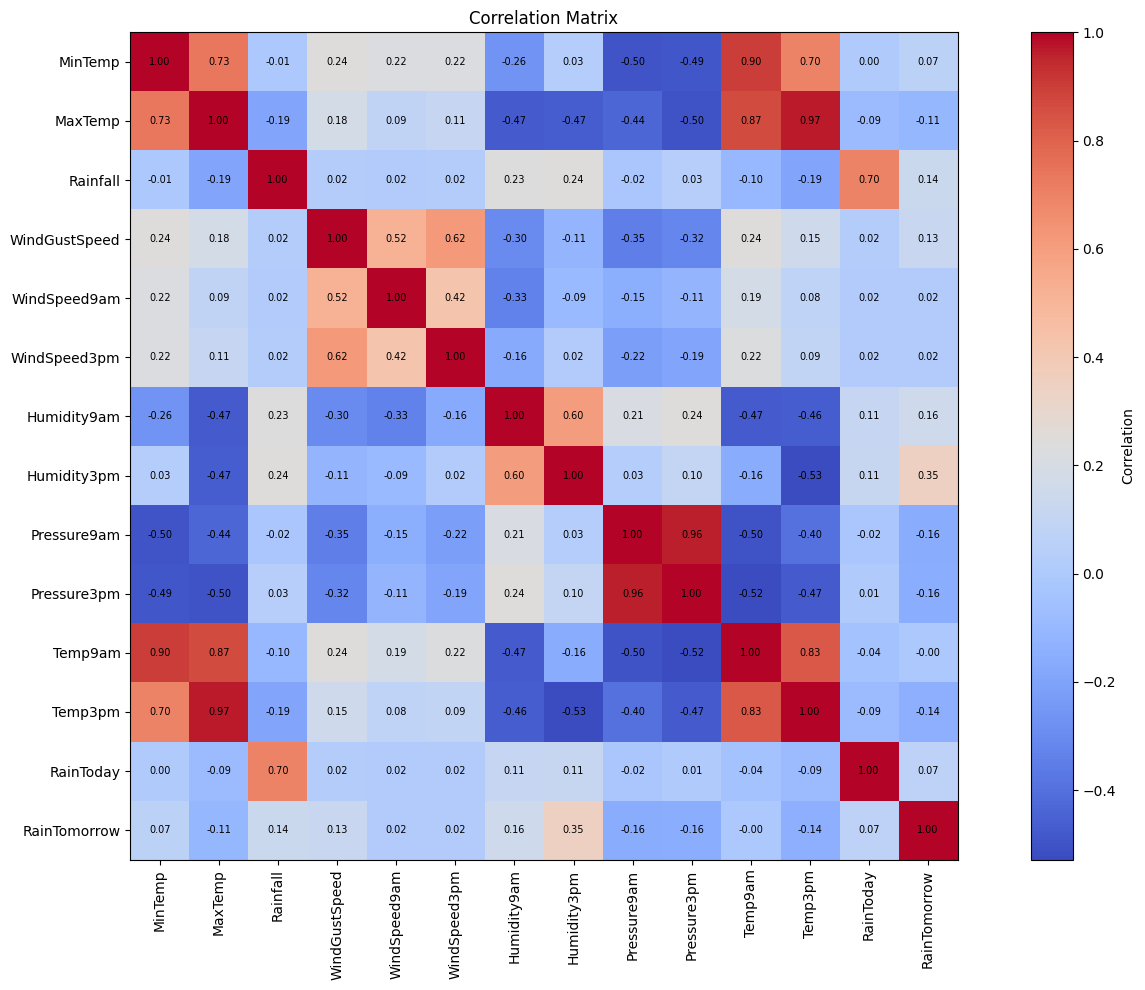

In [11]:
#correlation matrix
correlation = df_clean.corr(numeric_only=True)
plt.figure(figsize=(15, 10))
plt.imshow(correlation, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns,
           rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(j, i, f"{correlation.iloc[i, j]:.2f}",
                 ha="center", va="center", color="black", fontsize=7)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()
   



In [12]:
#feature engineering
#data extraction, categorical encoding, and feature selection
df_clean["Date"] = pd.to_datetime(df_clean["Date"],errors='coerce',dayfirst=True)
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Day"] = df_clean["Date"].dt.day
df_clean.drop("Date", axis=1, inplace=True)

df_clean = pd.get_dummies(df_clean, dtype=int)
print(df_clean)

         MinTemp   MaxTemp  Rainfall  WindGustSpeed  WindSpeed9am  \
0       0.534626  0.492611  0.400000           0.62      0.540541   
1       0.368421  0.546798  0.000000           0.62      0.108108   
2       0.520776  0.561576  0.000000           0.66      0.513514   
3       0.418283  0.618227  0.000000           0.22      0.297297   
4       0.648199  0.724138  0.666667           0.56      0.189189   
...          ...       ...       ...            ...           ...   
145455  0.240997  0.504926  0.000000           0.36      0.351351   
145456  0.263158  0.551724  0.000000           0.18      0.351351   
145457  0.313019  0.591133  0.000000           0.48      0.243243   
145458  0.379501  0.593596  0.000000           0.30      0.351351   
145459  0.576177  0.485222  0.000000           0.52      0.459459   

        WindSpeed3pm  Humidity9am  Humidity3pm  Pressure9am  Pressure3pm  ...  \
0           0.685714     0.641975     0.212121     0.147436     0.211726  ...   
1        

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X = df_clean.drop("Rainfall", axis=1)
y = df_clean["Rainfall"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 0.07429470642081501
MSE: 0.01473773674251613
R2 Score: 0.5517591007595558


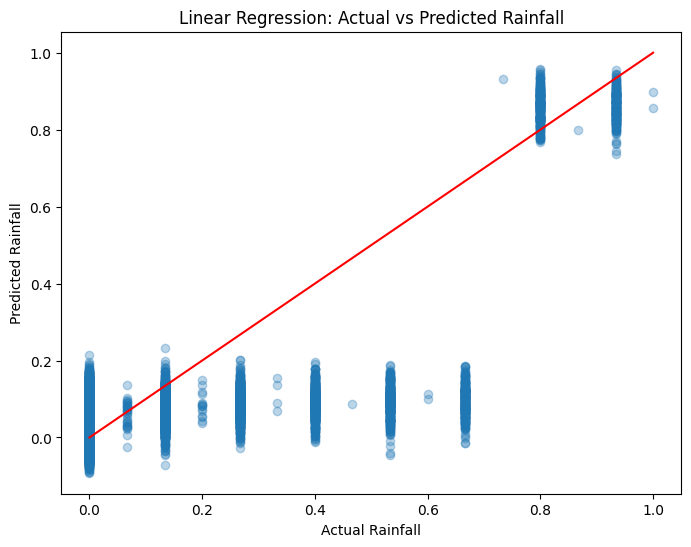

In [14]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.xlabel("Actual Rainfall")
plt.ylabel("Predicted Rainfall")
plt.title("Linear Regression: Actual vs Predicted Rainfall")
plt.show()